# 01 · Quick start

This notebook walks through the two tools of **GSTARX-PW** on a small simulated panel whose true
neighbourhood is *not* the one an analyst would assume:

1. the **Wald test** of a pre-specified weight matrix $W^0$, calibrated by the two-stage residual bootstrap;
2. the **GSTARX-PW estimator** of the row-normalized, non-negative weight matrix.

The model is $Y_t = B'x_t + Z_t$ (exogenous stage) and $Z_t = (\Phi_0 + \Phi_1 W) Z_{t-1} + a_t$ (space–time stage).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # or: pip install -e .  (from the repository root)
import numpy as np
import matplotlib.pyplot as plt
import gstarx_pw as g
from gstarx_pw.plotting import set_style, plot_links, plot_bootstrap, plot_heatmaps, OKABE_ITO as C
set_style()

## 1. Simulate a panel
Twelve locations at random positions. The analyst assumes inverse-distance weights; the truth links every location to three randomly chosen partners.

In [2]:
rng = np.random.default_rng(2026)
N, T = 12, 300
lat, lon = rng.uniform(-8.3, -6.7, N), rng.uniform(111.0, 114.4, N)
W0 = g.inverse_distance(lat, lon)          # the pre-specified matrix (the null hypothesis)
W_true = g.sparse_matrix(N, rng)           # the true neighbourhood
A = np.diag(rng.uniform(0.45, 0.65, N)) + rng.uniform(0.20, 0.40, N)[:, None] * W_true
X = g.design_generic(T)                    # intercept, two harmonics, a moving calendar block
Y = X @ rng.normal(0, 0.5, (X.shape[1], N)) + g.simulate(A, T, rng)
print(Y.shape)

(300, 12)


## 2. Exogenous stage
Ordinary least squares on the deterministic design; the space–time tools work on the residual panel $\hat Z_t$.

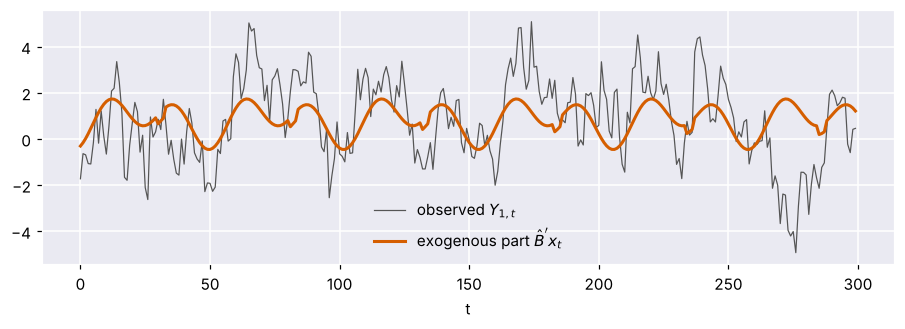

In [3]:
B, Zhat = g.exogenous_stage(Y, X)
M = g.annihilator(X)                       # lets the bootstrap re-estimate this stage on every bootstrap panel
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(Y[:, 0], color='#555555', lw=0.8, label='observed $Y_{1,t}$')
ax.plot(X @ B[:, 0], color=C[1], lw=2, label='exogenous part $\\hat B\'x_t$')
ax.legend(); ax.set_xlabel('t'); plt.show()

## 3. Test the pre-specified matrix
Under $H_0: W = W^0$ the statistic $\mathcal W_{\rm tot}=\sum_i \mathcal W_i$ is calibrated by the two-stage bootstrap. As a control we also test the true matrix.

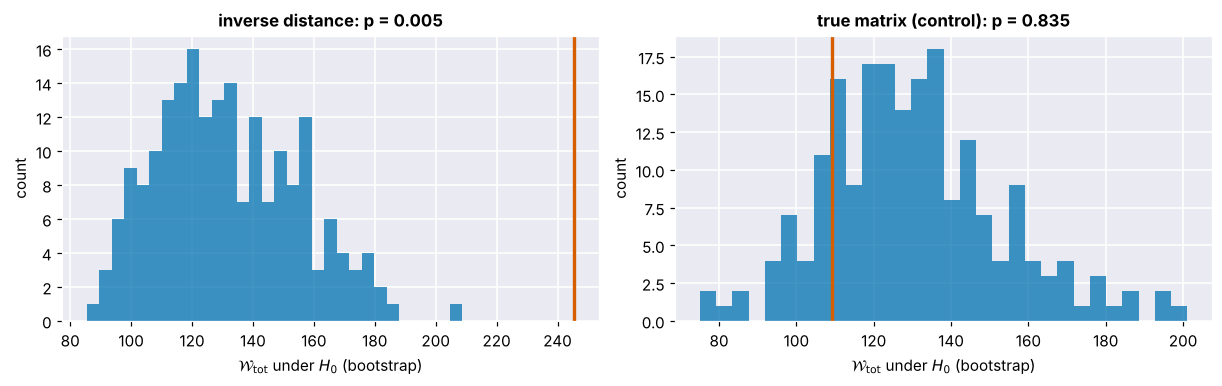

In [4]:
p, Wi, Wb = g.bootstrap_test(Zhat, W0, M, rng, B=199, return_boot=True)
p_true, Wi_true, Wb_true = g.bootstrap_test(Zhat, W_true, M, rng, B=199, return_boot=True)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
plot_bootstrap(ax[0], Wb, Wi.sum(), p, title=f'inverse distance: p = {p:.3f}')
plot_bootstrap(ax[1], Wb_true, Wi_true.sum(), p_true, title=f'true matrix (control): p = {p_true:.3f}')
plt.show()

## 4. Estimate the neighbourhood
The penalty $\kappa$ is chosen by one-step-ahead validation inside the training window ($\kappa=0$: constrained VAR; $\kappa\to\infty$: the prior).

selected kappa: 0.1
MAE of the weights  prior: 0.1403   GSTARX-PW: 0.0773


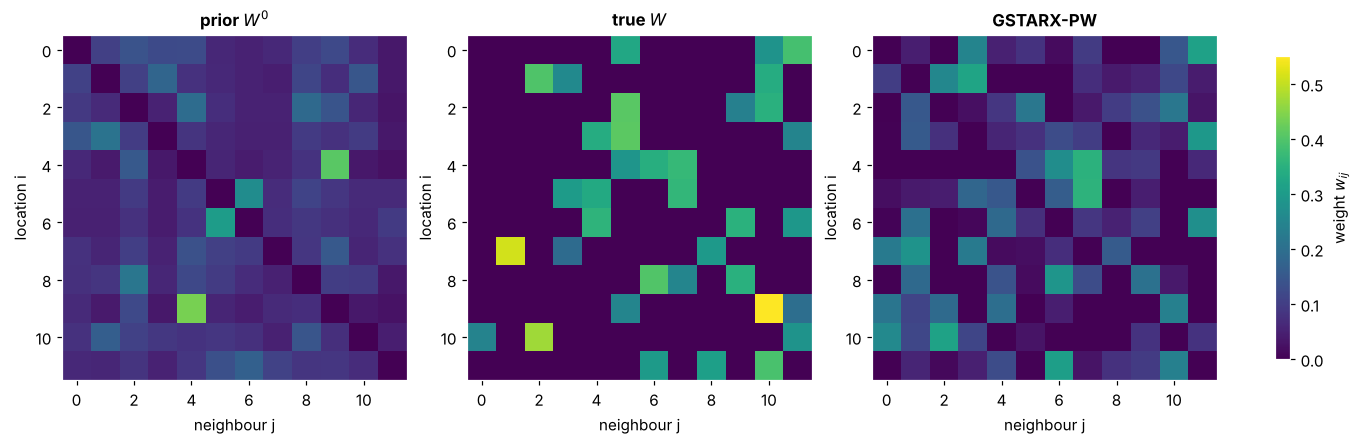

In [5]:
kappa, fit, curve = g.select_kappa(Zhat, W0, return_curve=True)
print('selected kappa:', kappa)
print('MAE of the weights  prior: %.4f   GSTARX-PW: %.4f' % (g.mae_offdiag(W0, W_true), g.mae_offdiag(fit['W'], W_true)))
fig, ax = plot_heatmaps([W0, W_true, fit['W']], ['prior $W^0$', 'true $W$', 'GSTARX-PW'])
plt.show()

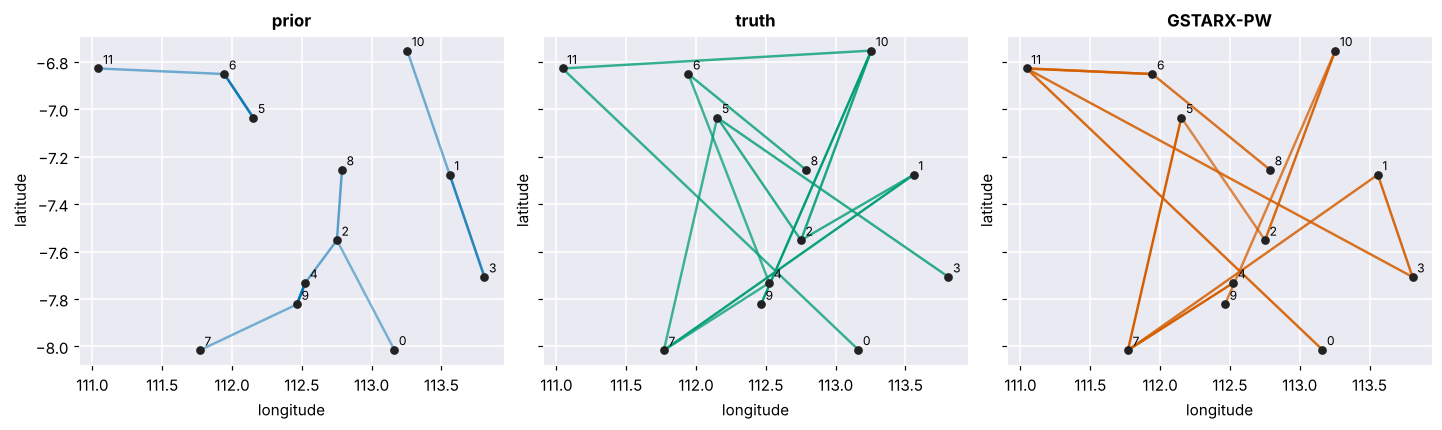

the strongest estimated link is a true link for 12 of 12 locations


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, constrained_layout=True)
for a, (W, t, c) in zip(ax, [(W0, 'prior', C[0]), (W_true, 'truth', C[2]), (fit['W'], 'GSTARX-PW', C[1])]):
    plot_links(a, lat, lon, W, k=1, color=c, labels=[str(i) for i in range(N)]); a.set_title(t)
plt.show()
hits = sum(W_true[i, int(np.argmax(fit['W'][i]))] > 0 for i in range(N))
print(f'the strongest estimated link is a true link for {hits} of {N} locations')